# Analyse sémantique

Dans ce notebook, nous allons explorer différentes méthodes de NLP pour choisir celle qui donne les meilleurs résultats :
- Bag of Words : 1 mot = 1 occurence
- TF-IDF : même principe, mais pondère les mots en fonction de leur rareté dans le corpus.
- N-2 : décompte les combinaisons de 2 mots (ex : très bien)
- ANNFIN : Donne un score émotionnel aux mots
- LDA : trouve les catégories.

https://regenerativetoday.com/countvectorizer-to-extract-features-from-texts-in-python-in-details/
https://towardsdatascience.com/basics-of-countvectorizer-e26677900f9c/
https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html
https://www.projectpro.io/recipes/use-count-vectorizer
https://stackoverflow.com/questions/44083683/countvectorizer-with-pandas-dataframe


In [40]:
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import matplotlib.pyplot as plt


In [41]:
df = pd.read_csv('df_preprocessed.csv')
df

,avis,dates,series,notes,plateforme,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght,tokens,tokens_lemmatized
0,Honest Opinion - Turns out Westeros is way mor...,2026-01-24,A Knight of the Seven Kingdoms,8.0,Imdb,1,0,0,0,0,0,419,honest opinion turns westeros way interesting ...,honest opinion turn westeros way interesting e...
1,"So Far, So Good (Don't Screw It Up) - The firs...",2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,1,0,0,0,0,638,far good screw first episode knight seven king...,far good screw first episode knight seven king...
2,A proper return to Westeros - I stayed up for ...,2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,1,0,0,0,0,1334,proper return westeros stayed 3 uk premiere on...,proper return westeros stayed 3 uk premiere on...
3,The only disappointment i had with ep 1 - Its ...,2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,0,1,0,1,0,404,disappointment ep 1 42 minuts expected hour ho...,disappointment ep 1 42 minuts expected hour ho...
4,Really freaking good with only one bad moment ...,2026-01-19,A Knight of the Seven Kingdoms,9.0,Imdb,1,1,0,0,0,0,1964,really freaking good one bad moment far knight...,really freaking good one bad moment far knight...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1407,Mediocre filmmaking - Weak script in combinati...,2025-10-29,King & Conqueror,1.0,Imdb,-1,0,1,0,1,0,349,mediocre filmmaking weak script combination we...,mediocre filmmaking weak script combination we...
1408,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,3.0,Imdb,-1,0,0,0,2,0,526,drunk history many reviewers noted events noth...,drunk history many reviewer noted event nothin...
1409,I get it... -,2026-02-26,King & Conqueror,7.0,Imdb,1,0,0,0,0,0,14,get,get
1410,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,3.0,Imdb,-1,2,0,0,0,0,322,realism earl military crews count 5 8 soldiers...,realism earl military crew count 5 8 soldier s...


In [42]:
# Identification des valeurs nulles
print(df.isna().sum())
df[df['tokens_lemmatized'].isna()]

avis                              0
dates                             0
series                            0
notes                             0
plateforme                        0
notes_3                           0
nb_capital_words                  0
nb_exclamation_points             0
nb_exclamation_points_chains      0
nb_interrogation_points           0
nb_interrogation_points_chains    0
lenght                            0
tokens                            2
tokens_lemmatized                 2
dtype: int64


,avis,dates,series,notes,plateforme,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght,tokens,tokens_lemmatized
329,👌 -,2026-02-07,A Knight of the Seven Kingdoms,10.0,Imdb,1,0,0,0,0,0,4,NaN,NaN
766,"No, no, no, -",2026-02-23,A Knight of the Seven Kingdoms,8.0,Imdb,1,0,0,0,0,0,14,NaN,NaN


In [43]:
# Suppression valeurs nulles et réinitialisation de l'index
df = df.dropna()
df = df.reset_index()

In [44]:
# Vectoriser en conservant les 100 mots les plus cités
vectorizer = CountVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'])

count_matrix = vectorizer.fit_transform(df['tokens_lemmatized'])
print(count_matrix.shape)
print(vectorizer.vocabulary_)

(1410, 100)
{'westeros': np.int64(94), 'way': np.int64(92), 'every': np.int64(26), 'minute': np.int64(55), 'dragon': np.int64(15), 'throne': np.int64(84), 'drama': np.int64(16), 'well': np.int64(93), 'heart': np.int64(39), 'epic': np.int64(22), 'like': np.int64(49), 'honor': np.int64(41), 'far': np.int64(29), 'good': np.int64(35), 'first': np.int64(31), 'episode': np.int64(23), 'knight': np.int64(47), 'seven': np.int64(72), 'kingdom': np.int64(46), 'start': np.int64(77), 'feel': np.int64(30), 'series': np.int64(70), 'martin': np.int64(54), 'work': np.int64(96), 'storytelling': np.int64(80), 'made': np.int64(51), 'house': np.int64(43), 'never': np.int64(59), 'season': np.int64(67), 'game': np.int64(32), 'book': np.int64(9), 'got': np.int64(36), 'ser': np.int64(69), 'dunk': np.int64(18), 'would': np.int64(98), 'give': np.int64(34), 'know': np.int64(48), 'story': np.int64(79), 'much': np.int64(57), 'make': np.int64(52), 'plot': np.int64(63), 'time': np.int64(85), 'fan': np.int64(28), 'cha

In [45]:
count_array = count_matrix.toarray()

count_df = pd.DataFrame(data=count_array, columns=vectorizer.get_feature_names_out())
count_df

,acting,action,actor,also,amazing,back,battle,best,better,book,...,watch,watching,way,well,westeros,without,work,world,would,writing
0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,0,0,3,...,0,0,0,0,2,0,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,1,1,2,1,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1405,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1406,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1407,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1408,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [46]:
# Mots qui reviennent le plus
count_df.sum(axis=0).sort_values(ascending=False).head(20)

show         1210
episode      1160
character     860
series        849
story         812
feel          708
like          636
knight        633
got           593
throne        588
game          547
good          539
egg           435
season        428
world         426
kingdom       426
great         419
seven         404
first         366
westeros      366
dtype: int64

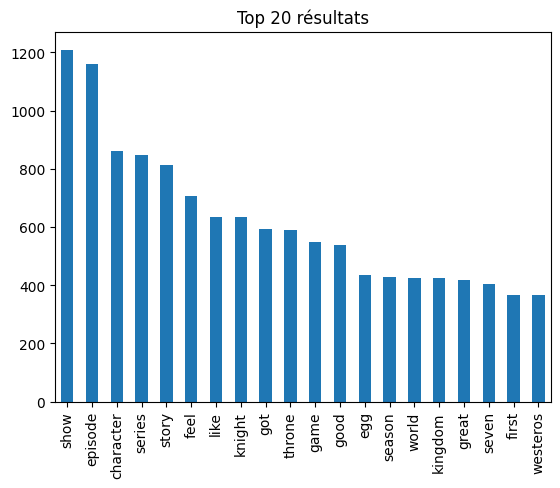

In [47]:
top_n = 20
count_df.sum(axis=0).sort_values(ascending=False).head(top_n).plot(kind='bar')
plt.title(f"Top {top_n} résultats")
plt.show()

Cette méthode est intéressante mais nous laisse sur notre fin. Effectivement, 'show' et 'épisode' sont compréhensibles avec les mots qui suivent, alors que character ou story peuvent d'interpréter.

Nous essayerons donc la méthode TF-IDF puis des N-words.

In [48]:
tfidf_vectorizer = TfidfVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'],
                             norm=None) # Ne normalise pas les réponses

tfidf_matrix = tfidf_vectorizer.fit_transform(df['tokens_lemmatized'])

print(tfidf_matrix.shape)
print(tfidf_vectorizer.vocabulary_)

(1410, 100)
{'westeros': np.int64(94), 'way': np.int64(92), 'every': np.int64(26), 'minute': np.int64(55), 'dragon': np.int64(15), 'throne': np.int64(84), 'drama': np.int64(16), 'well': np.int64(93), 'heart': np.int64(39), 'epic': np.int64(22), 'like': np.int64(49), 'honor': np.int64(41), 'far': np.int64(29), 'good': np.int64(35), 'first': np.int64(31), 'episode': np.int64(23), 'knight': np.int64(47), 'seven': np.int64(72), 'kingdom': np.int64(46), 'start': np.int64(77), 'feel': np.int64(30), 'series': np.int64(70), 'martin': np.int64(54), 'work': np.int64(96), 'storytelling': np.int64(80), 'made': np.int64(51), 'house': np.int64(43), 'never': np.int64(59), 'season': np.int64(67), 'game': np.int64(32), 'book': np.int64(9), 'got': np.int64(36), 'ser': np.int64(69), 'dunk': np.int64(18), 'would': np.int64(98), 'give': np.int64(34), 'know': np.int64(48), 'story': np.int64(79), 'much': np.int64(57), 'make': np.int64(52), 'plot': np.int64(63), 'time': np.int64(85), 'fan': np.int64(28), 'cha

In [49]:
tfidf_array = tfidf_matrix.toarray()

tfidf_df = pd.DataFrame(data=tfidf_array, columns=tfidf_vectorizer.get_feature_names_out())
tfidf_df

,acting,action,actor,also,amazing,back,battle,best,better,book,...,watch,watching,way,well,westeros,without,work,world,would,writing
0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.00000,2.881416,2.895468,2.783994,0.0,0.000000,0.000000,0.00000,0.0
1,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.00000,2.881416,0.000000,0.000000,0.0,3.533555,0.000000,0.00000,0.0
2,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,9.867628,...,0.000000,0.00000,0.000000,0.000000,5.567988,0.0,0.000000,0.000000,3.12809,0.0
3,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.00000,0.0
4,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,2.96885,2.881416,5.790935,2.783994,0.0,0.000000,2.585627,3.12809,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1405,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,2.763116,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.00000,0.0
1406,0.0,0.0,0.000000,0.0,0.0,0.0,3.542524,0.0,0.0,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.00000,0.0
1407,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.00000,0.0
1408,0.0,0.0,3.456263,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.00000,0.0


In [50]:
# Mots qui reviennent le plus
tfidf_df.sum(axis=0).sort_values(ascending=False).head(29)

show         2191.439968
episode      2136.579721
series       1752.157565
character    1651.674808
story        1625.687912
feel         1611.197754
knight       1463.421749
like         1387.317118
got          1352.509722
throne       1323.375775
good         1276.746313
game         1251.795611
season       1108.132006
world        1101.477214
egg          1095.640014
kingdom      1079.921183
great        1079.050763
seven        1039.040063
westeros     1018.941735
first         965.846859
dunk          938.504539
really        916.448939
make          914.673917
time          886.313086
best          879.627558
dragon        861.816635
watch         823.408635
love          782.740195
well          775.985337
dtype: float64

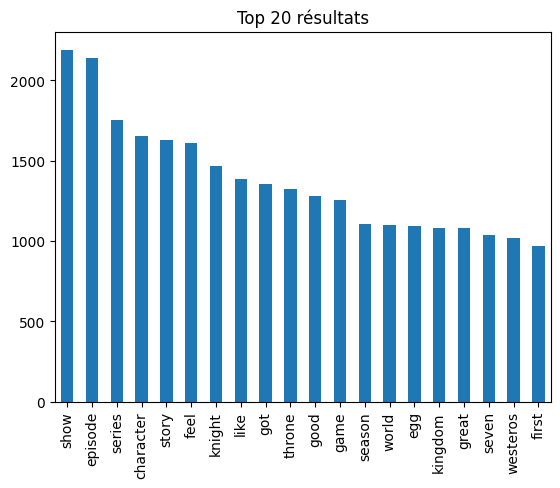

In [51]:
top_n = 20
tfidf_df.sum(axis=0).sort_values(ascending=False).head(top_n).plot(kind='bar')
plt.title(f"Top {top_n} résultats")
plt.show()

## Ngrams

(1410, 100)
{'first episode': np.int64(31), 'episode knight': np.int64(17), 'knight seven': np.int64(52), 'seven kingdom': np.int64(74), 'feel like': np.int64(26), 'george martin': np.int64(37), 'return westeros': np.int64(70), 'house dragon': np.int64(48), 'second season': np.int64(72), 'game throne': np.int64(36), 'read book': np.int64(68), 'peter claffey': np.int64(67), 'feel authentic': np.int64(25), 'long time': np.int64(55), 'well written': np.int64(96), 'first season': np.int64(33), 'main character': np.int64(59), 'show like': np.int64(79), 'looking forward': np.int64(57), 'two episode': np.int64(92), 'dunk egg': np.int64(12), 'hedge knight': np.int64(45), 'song ice': np.int64(83), 'ice fire': np.int64(49), 'ever seen': np.int64(22), 'short episode': np.int64(75), 'feel personal': np.int64(28), 'really good': np.int64(69), 'world building': np.int64(97), 'breath fresh': np.int64(5), 'fresh air': np.int64(35), '30 minute': np.int64(0), 'well done': np.int64(95), 'ser duncan': np.

,30 minute,absolute cinema,amazing show,best series,best show,breath fresh,character development,character driven,character feel,dexter sol,...,true knight,tv show,two episode,wait see,waste time,well done,well written,world building,world feel,world westeros
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1405,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1406,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1407,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1408,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


game throne              534
seven kingdom            382
knight seven             345
house dragon             158
feel like                155
dunk egg                 153
first episode            145
ser duncan               100
george martin             88
duncan tall               84
character driven          71
hedge knight              64
main character            60
30 minute                 52
world westeros            48
character development     47
tv show                   46
throne universe           41
read book                 41
got universe              41
must watch                41
world building            40
short episode             39
episode short             38
looking forward           38
best show                 36
good show                 36
every episode             35
look like                 35
dtype: int64


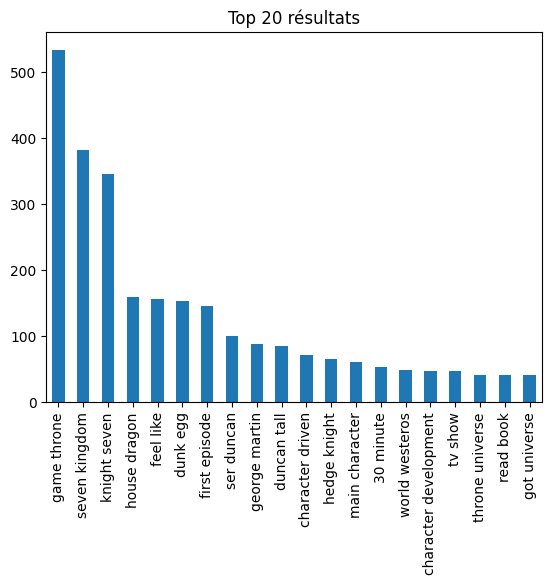

In [56]:
vectorizer_bigrams = CountVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'],
                             ngram_range=(2,2))

bigrams_count_matrix = vectorizer_bigrams.fit_transform(df['tokens_lemmatized'])
print(bigrams_count_matrix.shape)
print(vectorizer_bigrams.vocabulary_)

bigrams_array = bigrams_count_matrix.toarray()
bigrams_df = pd.DataFrame(data=bigrams_array, columns=vectorizer_bigrams.get_feature_names_out())
display(bigrams_df)

print(bigrams_df.sum(axis=0).sort_values(ascending=False).head(29))

top_n = 20
bigrams_df.sum(axis=0).sort_values(ascending=False).head(top_n).plot(kind='bar')
plt.title(f"Top {top_n} résultats")
plt.show()


(1410, 100)
{'first episode': np.int64(31), 'episode knight': np.int64(17), 'knight seven': np.int64(52), 'seven kingdom': np.int64(74), 'feel like': np.int64(26), 'george martin': np.int64(37), 'return westeros': np.int64(70), 'house dragon': np.int64(48), 'second season': np.int64(72), 'game throne': np.int64(36), 'read book': np.int64(68), 'peter claffey': np.int64(67), 'feel authentic': np.int64(25), 'long time': np.int64(55), 'well written': np.int64(96), 'first season': np.int64(33), 'main character': np.int64(59), 'show like': np.int64(79), 'looking forward': np.int64(57), 'two episode': np.int64(92), 'dunk egg': np.int64(12), 'hedge knight': np.int64(45), 'song ice': np.int64(83), 'ice fire': np.int64(49), 'ever seen': np.int64(22), 'short episode': np.int64(75), 'feel personal': np.int64(28), 'really good': np.int64(69), 'world building': np.int64(97), 'breath fresh': np.int64(5), 'fresh air': np.int64(35), '30 minute': np.int64(0), 'well done': np.int64(95), 'ser duncan': np.

,30 minute,absolute cinema,amazing show,best series,best show,breath fresh,character development,character driven,character feel,dexter sol,...,true knight,tv show,two episode,wait see,waste time,well done,well written,world building,world feel,world westeros
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,5.033178,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1405,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1406,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1407,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1408,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


game throne              1231.742205
seven kingdom             998.433126
knight seven              919.357826
feel like                 527.003672
house dragon              515.336176
dunk egg                  509.807173
first episode             502.361520
ser duncan                373.026537
george martin             337.322774
duncan tall               324.038803
character driven          284.252668
hedge knight              267.169057
main character            253.602136
30 minute                 236.001058
world westeros            213.378790
tv show                   209.906027
character development     205.900088
read book                 190.286578
throne universe           188.128185
got universe              188.128185
must watch                188.128185
world building            182.526980
short episode             182.072866
looking forward           177.404331
episode short             176.363169
best show                 172.307450
good show                 171.199670
l

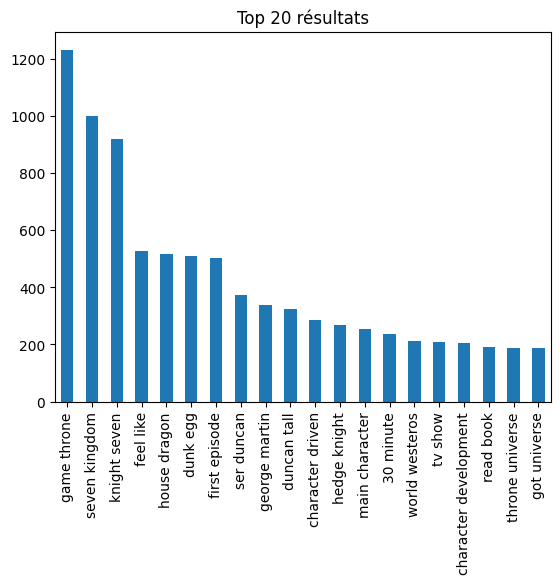

In [57]:
tfidf_bigrams = TfidfVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'],
                             norm=None,
                             ngram_range=(2,2))

bigrams_tfidf_matrix = tfidf_bigrams.fit_transform(df['tokens_lemmatized'])
print(bigrams_tfidf_matrix.shape)
print(tfidf_bigrams.vocabulary_)

tfidf_bigrams_array = bigrams_tfidf_matrix.toarray()
tfidf_bigrams_df = pd.DataFrame(data=tfidf_bigrams_array, columns=tfidf_bigrams.get_feature_names_out())
display(tfidf_bigrams_df)

print(tfidf_bigrams_df.sum(axis=0).sort_values(ascending=False).head(29))

top_n = 20
tfidf_bigrams_df.sum(axis=0).sort_values(ascending=False).head(top_n).plot(kind='bar')
plt.title(f"Top {top_n} résultats")
plt.show()